In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../data/processed/lululime_clean.csv")

df.head()


,transaction_id,date,time,customer_id,item_id,quantity,unit_price_paid,row_type,original_transaction_id,tier_at_purchase,...,interest_outdoor,interest_lifestyle,is_member,revenue,production_cost_amt,repair_cost_amt,redeemed_dollars,profit,is_repeat_visit,month
0,T1000001,2022-11-01,10:27:32,180984,T02,1,58.0,Purchase,NaN,Pre-loyalty,...,1,1,True,58.0,19,0,0.0,39.0,True,2022-11-01
1,T1000001,2022-11-01,10:27:32,180984,H02,1,98.0,Purchase,NaN,Pre-loyalty,...,1,1,True,98.0,35,0,0.0,63.0,True,2022-11-01
2,T1000002,2022-11-01,10:27:55,939082,A06,1,38.0,Purchase,NaN,Pre-loyalty,...,0,1,False,38.0,11,0,0.0,27.0,True,2022-11-01
3,T1000003,2022-11-01,10:52:43,884202,L02,1,118.0,Purchase,NaN,Pre-loyalty,...,0,0,True,118.0,44,0,0.0,74.0,True,2022-11-01
4,T1000003,2022-11-01,10:52:43,884202,H03,1,148.0,Purchase,NaN,Pre-loyalty,...,0,0,True,148.0,56,0,0.0,92.0,True,2022-11-01


In [3]:

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nTransaction types:")
print(df["row_type"].value_counts())

print("\nLoyalty tiers:")
print(df["tier_at_purchase"].value_counts())


Rows and columns: (350998, 40)

Column names:
['transaction_id', 'date', 'time', 'customer_id', 'item_id', 'quantity', 'unit_price_paid', 'row_type', 'original_transaction_id', 'tier_at_purchase', 'points_earned', 'points_redeemed', 'points_balance_after', 'notes', 'datetime', 'item_name', 'category', 'activity', 'season', 'price', 'production_cost', 'signup_date', 'age_band', 'home_area', 'acquisition_channel', 'interests', 'loyalty_join_date', 'interest_run', 'interest_yoga', 'interest_pilates', 'interest_outdoor', 'interest_lifestyle', 'is_member', 'revenue', 'production_cost_amt', 'repair_cost_amt', 'redeemed_dollars', 'profit', 'is_repeat_visit', 'month']

Transaction types:
row_type
Purchase           322769
Return              17528
Repair Drop-off      5480
Repair Pickup        5221
Name: count, dtype: int64

Loyalty tiers:
tier_at_purchase
Pre-loyalty    129582
Gold           107236
Member          47103
Silver          42421
Non-member      24656
Name: count, dtype: int64


In [4]:

# Convert dates into Python date format
df["date"] = pd.to_datetime(df["date"])
df["loyalty_join_date"] = pd.to_datetime(
    df["loyalty_join_date"]
)

# Combine item rows into transaction-level data
transactions = df.groupby(
    "transaction_id"
).agg(
    customer_id=("customer_id", "first"),
    date=("date", "first"),
    age_band=("age_band", "first"),
    loyalty_join_date=("loyalty_join_date", "first"),
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    points_redeemed=("points_redeemed", "sum"),
    row_type=("row_type", "first")
).reset_index()

transactions.head()


,transaction_id,customer_id,date,age_band,loyalty_join_date,revenue,profit,points_redeemed,row_type
0,T1000001,180984,2022-11-01,35-44,2024-06-18,156.0,102.0,0.0,Purchase
1,T1000002,939082,2022-11-01,25-34,NaT,38.0,27.0,0.0,Purchase
2,T1000003,884202,2022-11-01,35-44,2025-10-04,514.0,324.0,0.0,Purchase
3,T1000004,110076,2022-11-01,35-44,NaT,312.0,191.0,0.0,Purchase
4,T1000005,554756,2022-11-01,25-34,2024-07-07,108.0,66.0,0.0,Purchase


In [5]:

print("Original rows:", len(df))
print("Total transactions:", len(transactions))

print(transactions.head())


Original rows: 350998
Total transactions: 190156
  transaction_id  customer_id       date age_band loyalty_join_date  revenue  \
0       T1000001       180984 2022-11-01    35-44        2024-06-18    156.0   
1       T1000002       939082 2022-11-01    25-34               NaT     38.0   
2       T1000003       884202 2022-11-01    35-44        2025-10-04    514.0   
3       T1000004       110076 2022-11-01    35-44               NaT    312.0   
4       T1000005       554756 2022-11-01    25-34        2024-07-07    108.0   

   profit  points_redeemed  row_type  
0   102.0              0.0  Purchase  
1    27.0              0.0  Purchase  
2   324.0              0.0  Purchase  
3   191.0              0.0  Purchase  
4    66.0              0.0  Purchase  


In [6]:

before_start = "2023-06-01"
launch_date = "2024-06-01"
after_end = "2025-06-01"

before = transactions[
    (transactions["date"] >= before_start) &
    (transactions["date"] < launch_date)
]

after = transactions[
    (transactions["date"] >= launch_date) &
    (transactions["date"] < after_end)
]

print("Before transactions:", len(before))
print("After transactions:", len(after))


Before transactions: 44640
After transactions: 42989


In [7]:
print(df[["customer_id", "loyalty_join_date"]].drop_duplicates().head(10))

    customer_id loyalty_join_date
0        180984        2024-06-18
2        939082               NaT
3        884202        2025-10-04
8        110076               NaT
10       554756        2024-07-07
11       456919        2024-06-04
12       860162        2024-06-13
14       739697               NaT
16       254878        2024-09-08
18       510346               NaT


In [8]:
before["member_status"] = np.where(
    before["loyalty_join_date"].notna() &
    (before["loyalty_join_date"] <= before["date"]),
    "Member",
    "Non-member"
)

after["member_status"] = np.where(
    after["loyalty_join_date"].notna() &
    (after["loyalty_join_date"] <= after["date"]),
    "Member",
    "Non-member"
)

In [9]:
before_summary = before.groupby(
    ["customer_id", "age_band", "member_status"]
).agg(
    revenue_before=("revenue", "sum"),
    profit_before=("profit", "sum")
).reset_index()

after_summary = after.groupby(
    ["customer_id", "age_band", "member_status"]
).agg(
    revenue_after=("revenue", "sum"),
    profit_after=("profit", "sum")
).reset_index()

In [10]:
before_age = before_summary.groupby(
    ["age_band", "member_status"]
).agg(
    avg_revenue=("revenue_before", "mean"),
    avg_profit=("profit_before", "mean"),
    customers=("customer_id", "nunique")
).reset_index()

after_age = after_summary.groupby(
    ["age_band", "member_status"]
).agg(
    avg_revenue=("revenue_after", "mean"),
    avg_profit=("profit_after", "mean"),
    customers=("customer_id", "nunique")
).reset_index()

print(before_age)
print(after_age)

  age_band member_status  avg_revenue  avg_profit  customers
0    18-24    Non-member   657.294091  415.566250       1760
1    25-34    Non-member   867.140710  544.523884       2508
2    35-44    Non-member  1033.384679  647.418013       1560
3    45-54    Non-member  1060.410911  663.565017        889
4      55+    Non-member  1022.622500  642.370000        400
5  Unknown    Non-member   769.846853  481.867832        143
   age_band member_status  avg_revenue  avg_profit  customers
0     18-24        Member   812.737236  478.747109        709
1     18-24    Non-member   196.290682  125.057024        719
2     25-34        Member  1166.601980  676.875908       1515
3     25-34    Non-member   241.036008  152.503772       1458
4     35-44        Member  1461.708939  838.447642       1018
5     35-44    Non-member   310.404369  195.098544       1030
6     45-54        Member  1572.155254  902.202355        552
7     45-54    Non-member   301.416814  189.926549        565
8       55+    

In [11]:
customers = df[
    ["customer_id", "age_band", "loyalty_join_date", "signup_date"]
].drop_duplicates("customer_id").copy()

customers["loyalty_join_date"] = pd.to_datetime(
    customers["loyalty_join_date"]
)

customers["signup_date"] = pd.to_datetime(
    customers["signup_date"]
)

customers["group"] = np.where(
    (customers["loyalty_join_date"] >= "2024-06-01") &
    (customers["loyalty_join_date"] < "2025-06-01"),
    "Member",
    "Non-member"
)

print(customers["group"].value_counts())

group
Non-member    10336
Member         4104
Name: count, dtype: int64


In [12]:
customers = customers[
    customers["signup_date"] < "2024-06-01"
].copy()

In [13]:
before_spending = before.groupby("customer_id").agg(
    revenue_before=("revenue", "sum"),
    profit_before=("profit", "sum")
)

after_spending = after.groupby("customer_id").agg(
    revenue_after=("revenue", "sum"),
    profit_after=("profit", "sum")
)

comparison = customers.merge(
    before_spending,
    on="customer_id",
    how="left"
)

comparison = comparison.merge(
    after_spending,
    on="customer_id",
    how="left"
)

comparison = comparison.fillna({
    "revenue_before": 0,
    "profit_before": 0,
    "revenue_after": 0,
    "profit_after": 0
})

comparison.head()

,customer_id,age_band,loyalty_join_date,signup_date,group,revenue_before,profit_before,revenue_after,profit_after
0,180984,35-44,2024-06-18,2021-02-05,Member,6730.9,4121.9,7889.4,4201.4
1,939082,25-34,NaT,2020-06-16,Non-member,1252.0,816.0,0.0,0.0
2,884202,35-44,2025-10-04,2020-09-30,Non-member,610.0,382.0,128.0,81.0
3,110076,35-44,NaT,2021-12-10,Non-member,3188.0,2033.0,0.0,0.0
4,554756,25-34,2024-07-07,2020-08-14,Member,2700.5,1622.5,2516.0,1445.0


In [14]:
comparison["revenue_change"] = (
    comparison["revenue_after"] -
    comparison["revenue_before"]
)

comparison["profit_change"] = (
    comparison["profit_after"] -
    comparison["profit_before"]
)

comparison.head()

,customer_id,age_band,loyalty_join_date,signup_date,group,revenue_before,profit_before,revenue_after,profit_after,revenue_change,profit_change
0,180984,35-44,2024-06-18,2021-02-05,Member,6730.9,4121.9,7889.4,4201.4,1158.5,79.5
1,939082,25-34,NaT,2020-06-16,Non-member,1252.0,816.0,0.0,0.0,-1252.0,-816.0
2,884202,35-44,2025-10-04,2020-09-30,Non-member,610.0,382.0,128.0,81.0,-482.0,-301.0
3,110076,35-44,NaT,2021-12-10,Non-member,3188.0,2033.0,0.0,0.0,-3188.0,-2033.0
4,554756,25-34,2024-07-07,2020-08-14,Member,2700.5,1622.5,2516.0,1445.0,-184.5,-177.5


In [15]:
age_results = comparison.groupby(
    ["age_band", "group"]
).agg(
    avg_revenue_change=("revenue_change", "mean"),
    avg_profit_change=("profit_change", "mean"),
    customers=("customer_id", "nunique")
).reset_index()

print(age_results)

   age_band       group  avg_revenue_change  avg_profit_change  customers
0     18-24      Member         -123.071120        -120.381532        509
1     18-24  Non-member         -306.227217        -193.682266       1624
2     25-34      Member          231.724130          68.939348        920
3     25-34  Non-member         -361.740499        -227.662418       2126
4     35-44      Member          381.538424         130.914630        622
5     35-44  Non-member         -350.695843        -219.667608       1275
6     45-54      Member          461.879320         179.193768        353
7     45-54  Non-member         -406.856812        -254.572754        690
8       55+      Member          372.742466         124.249315        146
9       55+  Non-member         -373.917479        -234.814327        349
10  Unknown      Member          213.654545          60.981818         55
11  Unknown  Non-member         -193.792982        -122.371930        114


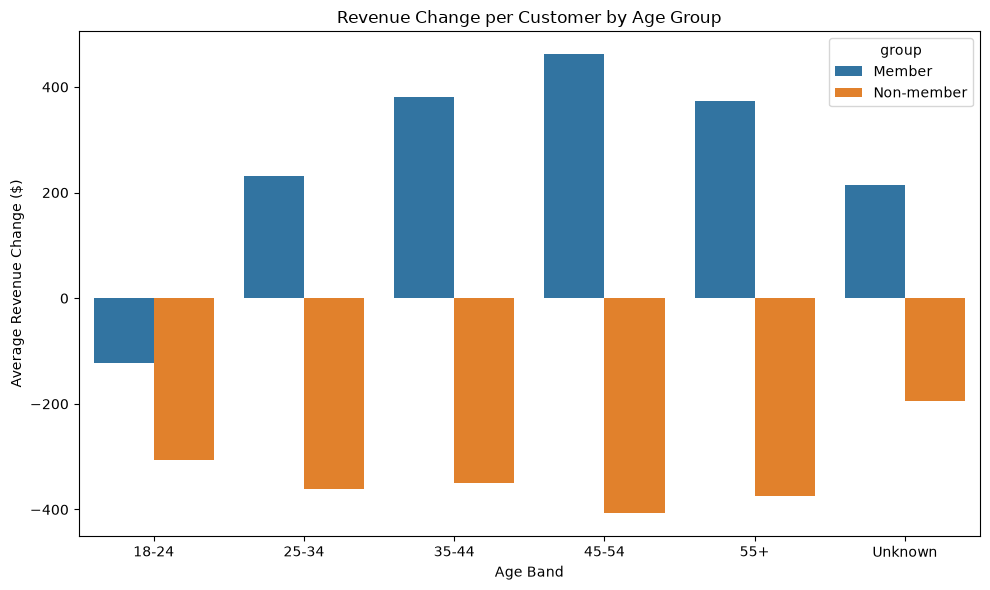

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_results,
    x="age_band",
    y="avg_revenue_change",
    hue="group"
)

plt.title("Revenue Change per Customer by Age Group")
plt.xlabel("Age Band")
plt.ylabel("Average Revenue Change ($)")
plt.tight_layout()
plt.show()